# `cluster-barcodes.ipynb`

Clustering FASTQ barcodes using the Levenshtein distance and DBSCAN clustering.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # for heatmaps
import Levenshtein # for distance computation
from sklearn.cluster import DBSCAN # for clustering
from tqdm import trange # for loop progress bar

In [41]:
def readFastq(filename):
    '''
    Read FASTQ file. Outputs two numpy arrays, `sequences` and `qualities`. `sequences` is an array of the nucleotide sequences
    
    Copied from this source: https://hossainlab.github.io/PY4B/notebooks/05-Working%20with%20FASTQ%20Sequence%20Data.html.
    The only change I made was to output numpy arrays at the end, instead of lists.
    '''
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline() # skip name line
            seq = fh.readline().rstrip() # read base sequence
            fh.readline() # skip placeholder line
            qual = fh.readline().rstrip() #base quality line
            if len(seq) == 0:
                break
            sequences.append(seq)
            qualities.append(qual)
    return np.array(sequences), np.array(qualities)

In [42]:
# extendedFrags contains trimmed *and* merged files (if I understand correctly)
sequences, qualities = readFastq('./fish17_s6_rep1_out.extendedFrags.fastq')
print(f'The first read sequence is: \'{sequences[0]}\'.')

The first read sequence is: 'AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGAGGAGTCGAGAGCGCGCTCGTCGATAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC'.


## Cluster using unique sequences in the file, not including counts.

In [43]:
# There are repeated sequences, but we just want the unique ones.
unique_seqs, seq_counts = np.unique(sequences, return_counts = True)
n_seqs = len(unique_seqs)

print(f'There are {len(sequences)} sequences in the file. {n_seqs} of them are unique.')

There are 13662 sequences in the file. 863 of them are unique.


In [44]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in range(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(unique_seqs[i], unique_seqs[j])

In [45]:
# The `distances` matrix contains the distance between every pair of reads.
distances[:5,:5]

array([[ 0.,  1., 73., 75., 48.],
       [ 1.,  0., 74., 76., 49.],
       [73., 74.,  0.,  2., 87.],
       [75., 76.,  2.,  0., 85.],
       [48., 49., 87., 85.,  0.]])

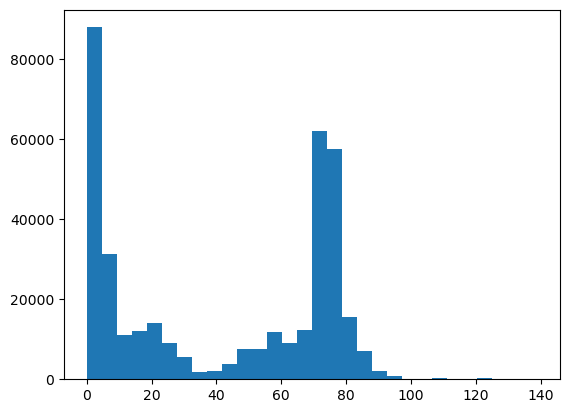

In [46]:
# Plot all the distances on a histogram. We see a bimodal distribution.
# Hopefully we can collapse all of the reads with very small distances.
plt.hist(distances[np.triu_indices(n_seqs)], bins=30);

<Axes: >

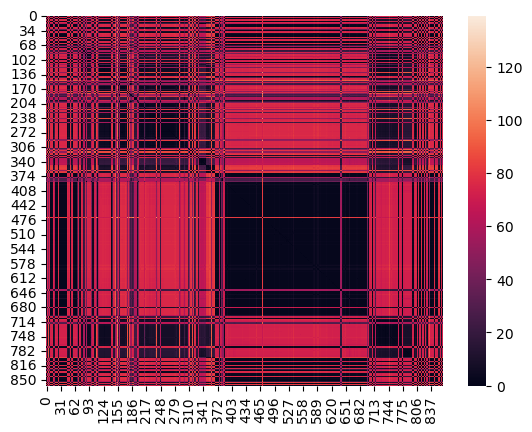

In [47]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [48]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [49]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 96 items
Cluster 0: 384 items
Cluster 1: 19 items
Cluster 2: 99 items
Cluster 3: 7 items
Cluster 4: 5 items
Cluster 5: 17 items
Cluster 6: 27 items
Cluster 7: 16 items
Cluster 8: 67 items
Cluster 9: 12 items
Cluster 10: 12 items
Cluster 11: 5 items
Cluster 12: 3 items
Cluster 13: 2 items
Cluster 14: 2 items
Cluster 15: 11 items
Cluster 16: 2 items
Cluster 17: 3 items
Cluster 18: 8 items
Cluster 19: 8 items
Cluster 20: 7 items
Cluster 21: 2 items
Cluster 22: 2 items
Cluster 23: 3 items
Cluster 24: 3 items
Cluster 25: 2 items
Cluster 26: 3 items
Cluster 27: 6 items
Cluster 28: 2 items
Cluster 29: 2 items
Cluster 30: 6 items
Cluster 31: 2 items
Cluster 32: 5 items
Cluster 33: 4 items
Cluster 34: 3 items
Cluster 35: 2 items
Cluster 36: 2 items
Cluster 37: 2 items


<Axes: >

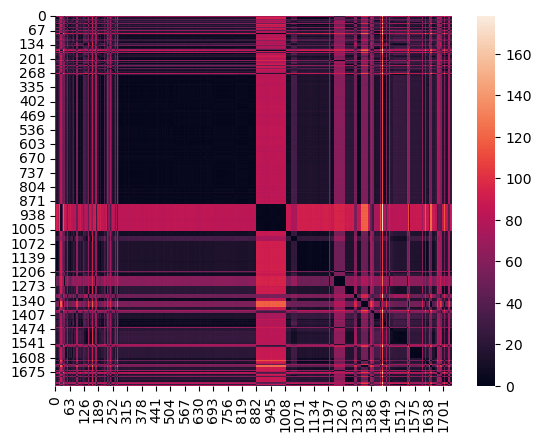

In [24]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)
# The giant black square in the middle represents one cluster.

<Axes: >

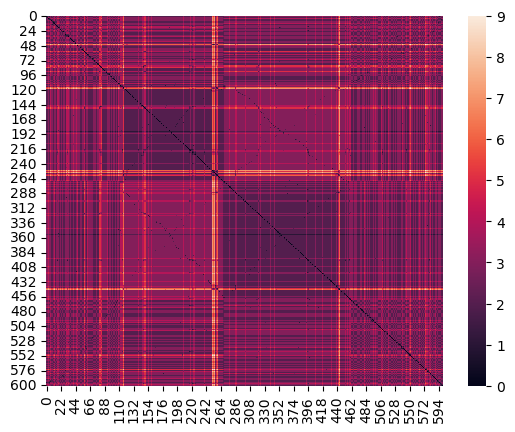

In [25]:
# Plot distances within the biggest cluster.
i = 0
indices_cluster_i = np.where(labels == i)[0]

cluster_i_seqs = unique_seqs[indices_cluster_i]
cluster_i_distances = distances[np.ix_(indices_cluster_i, indices_cluster_i)]

sns.heatmap(cluster_i_distances)

# Note that all of the sequences in this cluster have distance 4 or less from one another.

In [26]:
# Interestingly, the 120th sequence has distance 1 from almost every other sequence in this cluster,
# which may suggest that it is the "central" (or correct) sequence.
# This is clear in the heatmap above by the horizontal and vertical lines.
cluster_i_distances[120,:]

array([2., 2., 3., 3., 2., 3., 4., 3., 2., 3., 2., 3., 3., 3., 2., 2., 4.,
       2., 4., 3., 3., 2., 3., 4., 2., 3., 2., 3., 2., 2., 4., 3., 4., 4.,
       2., 3., 2., 3., 3., 3., 2., 4., 3., 2., 3., 4., 6., 3., 3., 2., 3.,
       2., 3., 2., 3., 4., 3., 4., 2., 2., 3., 3., 1., 2., 3., 2., 2., 3.,
       2., 2., 3., 3., 3., 4., 3., 2., 3., 3., 3., 2., 4., 3., 4., 5., 3.,
       2., 2., 2., 2., 2., 4., 2., 3., 2., 3., 3., 2., 2., 3., 3., 2., 3.,
       3., 3., 2., 2., 3., 2., 2., 4., 3., 2., 3., 3., 2., 3., 5., 6., 2.,
       2., 0., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 3., 2., 2., 2., 2., 2., 3., 4., 3., 4., 3., 4., 2., 2.,
       2., 3., 2., 2., 2., 2., 3., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       1., 2., 2., 3., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 3., 2., 2., 2., 2., 2., 2., 2., 2., 2., 3., 3., 2., 3.,
       2., 3., 2., 3., 2.

In [27]:
# I did the clustering in a way that ignored the number of occurances of each sequence,
# but here are the counts of each sequence in our big cluster.
counts_cluster_i = seq_counts[indices_cluster_i]
counts_cluster_i

# We see that one sequence has the most reads, suggesting that it is the correct
# sequence (and every other read has small errors).

array([   1,    1,    1,    1,    3,    3,    1,    2,    1,    4,    4,
          3,    1,    1,    1,    1,    2,    1,    1,    4,    1,    1,
          1,    1,    2,    1,    1,    1,    1,    1,    1,    9,    1,
          1,    2,    1,    1,    1,    1,    1,    1,    1,    2,    2,
          3,    1,    1,    1,    3,    1,    2,    1,    4,    1,    1,
          1,    1,    1,    1,    2,    2,    1,    1,    1,    6,    1,
          1,    1,    2,    2,    4,    2,    4,    1,    1,    1,    1,
          1,    1,    1,    3,    1,    1,    2,    1,    1,    1,    1,
          2,    1,    1,    2,    5,    1,    3,    1,    1,    1,    1,
          1,    4,    2,    1,    1,    1,    2,    3,    2,    2,    2,
          8,    1,    1,    2,    5,    1,    1,    1,    1,    6,    1,
          1,    1,    1,    1,    1,    1,    1,    3,    6,    1,    1,
          1,    1,    1,    1,    1,    2,    1,    1,    5,    1,    1,
          1,    1,    1,    1,   19,    1,   40,   

In [28]:
# Compute the index corresponding to this large count.
argmax_indices = np.where(counts_cluster_i == np.max(counts_cluster_i))[0]
if len(argmax_indices) > 1:
    raise Exception('There are multiple sequences that achieve the max read count. Deal with this somehow')
else:
    index_high_count = argmax_indices[0]

print(f'Within the cluster, the index of the sequence that has the most reads is {index_high_count}. It contains {counts_cluster_i[index_high_count]} reads.')

# Hey look! We've seen 120 before; it was the sequence that was the most 'central' in the cluster
# when looking at the heatmap

Within the cluster, the index of the sequence that has the most reads is 355. It contains 3045 reads.


In [29]:
# Print this 'central' sequence for the cluster.
print(f'The sequence of this \'central\' cluster is {cluster_i_seqs[index_high_count]}')

# It does not make much sense for me to look at the quality score of this sequence since it corresponds to ~3,000 individual reads.

The sequence of this 'central' cluster is AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATCGTCGACTATGGAGTCGTCAGCAGTACTACTGATGGAGTCGACAGCAGTGTGTGAGTCGAGAGTCGAGAGCATAGACATCGGTATGGAGTCGACTACAGTCGCTACGACTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC


In [30]:
# Check each cluster for the index of the most abundant sequence, as well as the sequence with the lowest total distance from all other sequences
for i in range(len(unique_labels) - 1):
    indices_cluster_i = np.where(labels == i)[0]
    cluster_i_seqs = unique_seqs[indices_cluster_i]
    cluster_i_distances = distances[np.ix_(indices_cluster_i, indices_cluster_i)]
    counts_cluster_i = seq_counts[indices_cluster_i]
    argmax_indices = np.where(counts_cluster_i == np.max(counts_cluster_i))[0]

    summed_distances = []
    for index in range(len(cluster_i_distances)):
        summed_distances.append(sum(cluster_i_distances[index,:]))
    distmin_indices = np.where(summed_distances == np.min(summed_distances))[0]

    print(f'{i}- size: {len(cluster_i_distances)}  max count: {argmax_indices}  min distance: {distmin_indices}')
# From this output, we can see that the sequence with the most occurances almost always has the minimum total distance from other reads as well (especially for larger clusters)

0- size: 601  max count: [355]  min distance: [355]
1- size: 130  max count: [54]  min distance: [54]
2- size: 24  max count: [9]  min distance: [9]
3- size: 24  max count: [18]  min distance: [18]
4- size: 139  max count: [47]  min distance: [47]
5- size: 6  max count: [4]  min distance: [4]
6- size: 4  max count: [1]  min distance: [1]
7- size: 15  max count: [12]  min distance: [12]
8- size: 46  max count: [16]  min distance: [16]
9- size: 39  max count: [16]  min distance: [16]
10- size: 16  max count: [2]  min distance: [2 8]
11- size: 14  max count: [4]  min distance: [4]
12- size: 3  max count: [2]  min distance: [2]
13- size: 29  max count: [20]  min distance: [20]
14- size: 8  max count: [4]  min distance: [4]
15- size: 3  max count: [2]  min distance: [2]
16- size: 3  max count: [1]  min distance: [1]
17- size: 2  max count: [1]  min distance: [0 1]
18- size: 11  max count: [4]  min distance: [4]
19- size: 26  max count: [8]  min distance: [ 8 19]
20- size: 3  max count: [0 1

In [40]:
np.where(labels == 0)[0]

array([   0,    2,    3,    6,    9,   10,   16,   17,   19,   20,   23,
         24,   26,   28,   31,   33,   34,   36,   37,   38,   43,   46,
         53,   54,   55,   56,   62,   65,   72,   75,   76,   78,   79,
         80,   85,   86,   89,   90,   91,   92,   95,   96,   97,  101,
        102,  108,  111,  112,  115,  116,  118,  120,  121,  122,  123,
        125,  126,  127,  128,  130,  131,  132,  133,  134,  135,  136,
        137,  138,  139,  141,  142,  143,  144,  145,  146,  147,  148,
        151,  189,  190,  191,  192,  193,  194,  195,  196,  197,  198,
        199,  200,  201,  202,  205,  206,  207,  208,  209,  210,  211,
        212,  215,  216,  217,  218,  219,  220,  221,  222,  223,  224,
        225,  226,  228,  229,  230,  231,  232,  233,  234,  235,  236,
        237,  238,  239,  240,  241,  242,  243,  244,  245,  246,  247,
        248,  249,  250,  251,  252,  254,  255,  256,  257,  258,  259,
        261,  263,  264,  265,  266,  267,  268,  2

In [31]:
labels

array([ 0,  1,  0, ...,  1,  0, -1], shape=(1740,))

<Axes: >

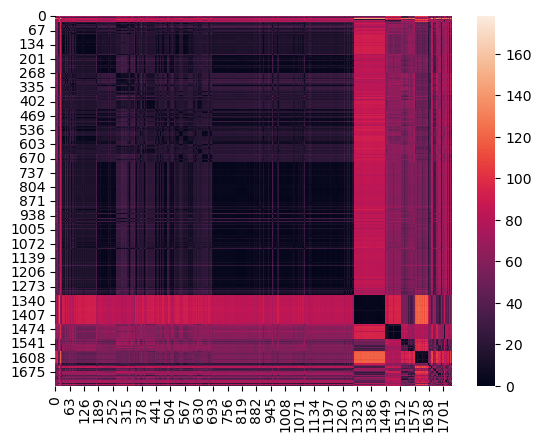

In [32]:
# Here is the same plot but with a larger clustering parameter value.
# This results in fewer clusters.

eps = 10
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')
labels = db.fit_predict(distances)

sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]
sns.heatmap(reordered_distances)

In [33]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 29 items
Cluster 0: 1282 items
Cluster 1: 137 items
Cluster 2: 70 items
Cluster 3: 28 items
Cluster 4: 32 items
Cluster 5: 56 items
Cluster 6: 6 items
Cluster 7: 6 items
Cluster 8: 3 items
Cluster 9: 5 items
Cluster 10: 3 items
Cluster 11: 3 items
Cluster 12: 2 items
Cluster 13: 5 items
Cluster 14: 2 items
Cluster 15: 9 items
Cluster 16: 13 items
Cluster 17: 2 items
Cluster 18: 2 items
Cluster 19: 2 items
Cluster 20: 3 items
Cluster 21: 2 items
Cluster 22: 3 items
Cluster 23: 2 items
Cluster 24: 2 items
Cluster 25: 2 items
Cluster 26: 9 items
Cluster 27: 2 items
Cluster 28: 3 items
Cluster 29: 5 items
Cluster 30: 5 items
Cluster 31: 2 items
Cluster 32: 3 items


## Cluster using ALL sequences, including duplicates

This takes a lot longer to run...

In [178]:
n_seqs = len(sequences)
print(f'There are {n_seqs} sequences.')

There are 5341 sequences.


In [179]:
# Compute Levenshtein distance between every pair of reads.
# for 5341 reads, this takes about a minute to run.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(sequences[i], sequences[j])

100%|██████████████████████████████████████| 5341/5341 [00:46<00:00, 114.65it/s]


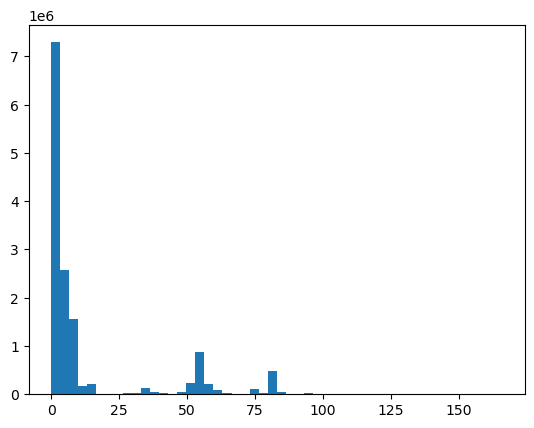

In [190]:
# Plot all the distances on a histogram.
plt.hist(distances[np.triu_indices(n_seqs)], bins=50);

# The left mode is a lot stronger here compared to when we removed duplicates - this makes sense to me.

<Axes: >

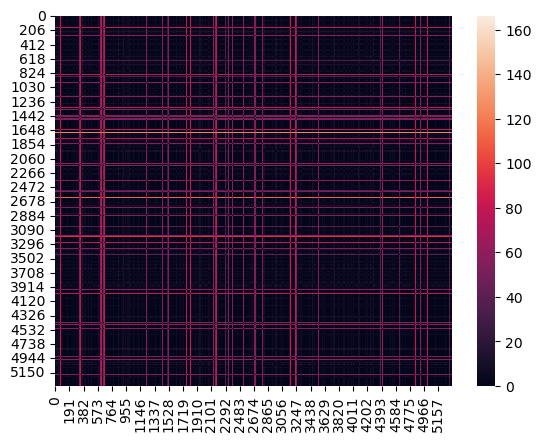

In [184]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [191]:
# Cluster
eps = 1.0
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [192]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# When we did not include duplicate sequences, we ended up with 18 clusters. Now, we have 33!

Cluster -1: 52 items
Cluster 0: 3651 items
Cluster 1: 6 items
Cluster 2: 857 items
Cluster 3: 195 items
Cluster 4: 113 items
Cluster 5: 2 items
Cluster 6: 194 items
Cluster 7: 33 items
Cluster 8: 53 items
Cluster 9: 41 items
Cluster 10: 3 items
Cluster 11: 13 items
Cluster 12: 16 items
Cluster 13: 8 items
Cluster 14: 21 items
Cluster 15: 3 items
Cluster 16: 11 items
Cluster 17: 9 items
Cluster 18: 6 items
Cluster 19: 3 items
Cluster 20: 3 items
Cluster 21: 9 items
Cluster 22: 5 items
Cluster 23: 8 items
Cluster 24: 2 items
Cluster 25: 3 items
Cluster 26: 4 items
Cluster 27: 3 items
Cluster 28: 2 items
Cluster 29: 2 items
Cluster 30: 4 items
Cluster 31: 2 items
Cluster 32: 2 items
Cluster 33: 2 items


<Axes: >

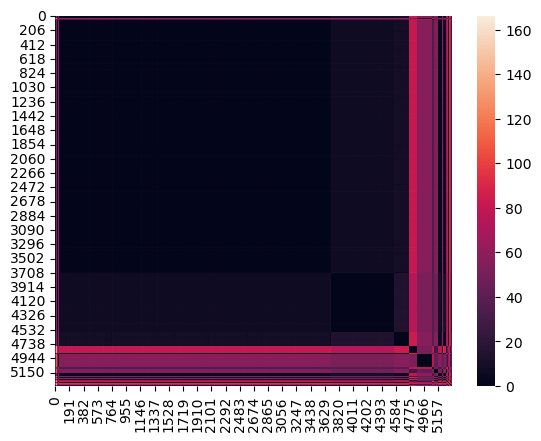

In [193]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)

# Don't be fooled - that big square in the middle is actually 3 clusters. You may have to squint to see it :)

In [194]:
# Still TBD whether it is better to cluster with or without duplicate sequences, or if it doesn't really matter.